# Step 5a — Climate x soil suitability on ERA5 (MIRCA2000 presence, original 5% pixel threshold), and its own validation

For every crop, combines the `4.a)_SVM_predict_ERA5_1deg` **continuous** climate-suitability
probability (`suit_proba`, before the 0.5 threshold used for the binary maps there) with the
GAEZ Module IV soil suitability (`1_SVM/2_soil_suitability_gaez`, SSR formula-audited
against the GAEZ v5 wiki, 0-100 rescaled to 0-1) on the same ERA5 1-deg grid: `combined =
climate_proba x soil_index`. A binary (suitable/not) version is then derived from the combined
score. The two sources use different land masks (climate: Natural Earth 25% rule; soil: HWSD2
native coverage), so a cell valid in one and not the other becomes NaN in the product --
no separate intersection step is needed, the multiplication handles it.
Two independent validations follow: against MIRCA2000 (real current cultivation, Section
2) and, new here, against GAEZ v4's own **combined** climate+soil+terrain suitability
index (Section 3) — unlike `2.b)`'s soil-only GAEZ comparison, this one is available for
maize *and* wheat.

**Important caveat, stated up front:** MIRCA2000 is the SVM's own training target, so
comparing the *climate* probability against it is not an independent test of the climate
model (a trained classifier is expected to reproduce its own training labels reasonably
well). What **is** a genuine, non-circular test is whether the **soil** layer (which the
SVM never saw during training) further improves that agreement, and whether the combined
map agrees with GAEZ's independently-built combined product.

In [1]:
import os; os.environ.setdefault("HDF5_USE_FILE_LOCKING", "FALSE")   # BDAP/EOS refuses HDF5 file locks ("NetCDF: HDF error")
# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  PARAMÈTRES — modifier ici, puis relancer les cellules marquées [RUN]  ║
# ╚══════════════════════════════════════════════════════════════════════════╝
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, xarray as xr, joblib, rasterio
from rasterio.windows import Window
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import roc_auc_score, roc_curve

BASE      = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "0_Input_data").is_dir())  # racine du projet (local ou BDAP)
import sys; sys.path.insert(0, str(BASE)); import crop_utils as cu   # helpers + config reader (project root)
CFG = cu.load_config()   # config/config_<profile>.json, written by 00_config_and_inventory.ipynb
ERA5_DIR    = BASE / "1_SVM" / "1_preprocessing_BIOvariables" / "1.1)_preprocessing_biovariables_ERA5" / "outputs_ERA5_MIRCA2000_threshold5pct"
CLIMATE_DIR = BASE / "1_SVM" / "4_SVM_predict" / "4.a)_SVM_predict_ERA5_1deg_MIRCA2000_threshold5pct" / "svm_predict_outputs_ERA5_1deg"
SOIL_DIR    = BASE / "1_SVM" / "2_soil_suitability_gaez" / "soil_suitability_outputs"
MODEL_DIR   = BASE / "1_SVM" / "3_SVM_train" / "3.a)_SVM_train_ERA5_MIRCA2000_threshold5pct" / "svm_train_outputs_mirca2000_threshold5pct"
# GAEZ v5 "SIX" mapset (Suitability index/class, total grid cell -- Module V, the real v5
# equivalent of the old v4 "Theme 4 si" product). HP8100 = 1981-2000 (confirmed via the FAO
# GISMGR API, PERIOD/members -- NOT 2001-2020 as earlier drafts of this notebook said).
# AgERA5, rain-fed only. Wheat is not split into spring/winter by GAEZ -- both compare
# against the same generic wheat file.
GAEZ_DIR  = cu.data_dir(CFG, "gaez_v5_hist")  # data path: see 00_config_and_inventory.ipynb
OUT_DIR   = BASE / "1_SVM" / "5_Suitability_climate_soil_combined_validation" / "5.a)_Apply_ERA5_validation_threshold5pct" / "era5_validation_outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)

CROPS = ['Maize_rf', 'Wheat-spring_rf', 'Wheat-winter_rf', 'Potato_rf']
GAEZ_CODE = {'Maize_rf': 'MZE', 'Wheat-spring_rf': 'WHE', 'Wheat-winter_rf': 'WHE', 'Potato_rf': 'WPO'}

# Two input levels, each soil layer compared to the matching GAEZ v5 SIX water-supply/input
# code (HRLM = high input rain-fed, LRLM = low input rain-fed). Our soil (2_GAEZ Module IV)
# now provides SSR for all 3 levels for every crop (previously High/Low were only computed
# for Maize_rf; fixed in 2.c) so this is no longer a High(GAEZ)-vs-Intermediate(ours) mismatch.
LEVELS = ['high', 'low']
GAEZ_WSIM = {'high': 'HRLM', 'low': 'LRLM'}
SOIL_SUFFIX = {'high': '_high', 'low': '_low'}
GAEZ_V5_SIX = {level: {crop: GAEZ_DIR / f'GAEZ-V5.RES05-SIX.HP8100.AGERA5.HIST.{GAEZ_CODE[crop]}.{wsim}.tif'
                      for crop in CROPS}
              for level, wsim in GAEZ_WSIM.items()}

print("Input files:")
_checks = ([CLIMATE_DIR / f'suitability_ERA5_{c}.nc' for c in CROPS]
          + [SOIL_DIR / f'soil_suitability_{c}_1deg_x0grid{SOIL_SUFFIX[lv]}.nc' for c in CROPS for lv in LEVELS]
          + [MODEL_DIR / f'svm_model_{c}.joblib' for c in CROPS]
          + [p for d in GAEZ_V5_SIX.values() for p in d.values()])
for p in _checks:
    print(f'  {"OK" if p.exists() else "MISSING"}: {p}')

Input files:
  OK: C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\1_SVM\4_SVM_predict\svm_predict_outputs_ERA5_1deg\suitability_ERA5_Maize_rf.nc
  OK: C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\1_SVM\4_SVM_predict\svm_predict_outputs_ERA5_1deg\suitability_ERA5_Wheat-spring_rf.nc
  OK: C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\1_SVM\4_SVM_predict\svm_predict_outputs_ERA5_1deg\suitability_ERA5_Wheat-winter_rf.nc
  OK: C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\1_SVM\4_SVM_predict\svm_predict_outputs_ERA5_1deg\suitability_ERA5_Potato_rf.nc
  OK: C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\1_SVM\2_soil_suitability_gaez\soil_suitability_outputs\soil_suitability_Maize_rf_1deg_x0grid_high.nc
  OK: C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\1_SVM\2_s

In [2]:
ds_grid = xr.open_dataset(ERA5_DIR / 'BIOvariables_ERA5_1981_2015_1deg_Maize_rf.nc')
target_lats_asc = ds_grid.lat.values
target_lons     = ds_grid.lon.values
ds_grid.close()

land_mask = np.zeros((len(target_lats_asc), len(target_lons)), dtype=bool)
for crop in CROPS:
    ds_c = xr.open_dataset(ERA5_DIR / f'BIOvariables_ERA5_1981_2015_1deg_{crop}.nc')
    land_mask |= np.isfinite(ds_c['BIO01'].values)
    ds_c.close()

nlat, nlon = len(target_lats_asc), len(target_lons)
LAT_MIN_EDGE, LAT_MAX_EDGE = target_lats_asc[0] - 0.5, target_lats_asc[-1] + 0.5
LON_MIN_EDGE, LON_MAX_EDGE = target_lons[0] - 0.5, target_lons[-1] + 0.5
ext = [LON_MIN_EDGE, LON_MAX_EDGE, LAT_MIN_EDGE, LAT_MAX_EDGE]

print(f"Grid: {nlat} lat x {nlon} lon, {land_mask.sum()} land cells")

Grid: 37 lat x 70 lon, 1332 land cells


## 1. Climate probability x soil index, per crop

In [3]:
def load_climate_proba(crop):
    """Continuous climate-suitability probability from 4.a)_SVM_predict_ERA5_1deg (suit_proba, 0-1)."""
    ds = xr.open_dataset(CLIMATE_DIR / f'suitability_ERA5_{crop}.nc')
    arr = ds['suit_proba'].values
    ds.close()
    return arr


def load_soil_suitability(crop, level):
    """GAEZ Module IV SSR, x.0 grid, for the given input level ('high'/'low'), 0-100 -> 0-1."""
    ds = xr.open_dataset(SOIL_DIR / f'soil_suitability_{crop}_1deg_x0grid{SOIL_SUFFIX[level]}.nc')
    # Wheat-spring/Wheat-winter files both keep the variable name 'soil_suitability_Wheat_rf'
    # (GAEZ soil doesn't distinguish the two seasons) -- read the file's one data variable
    # generically instead of assuming it matches the crop label.
    arr = ds[list(ds.data_vars)[0]].values / 100.0
    ds.close()
    return arr


# Continuous combination (climate_proba x soil_index/100), matching how GAEZ v5 itself combines
# climate and soil in Module V: the soil quality rating (SSR, continuous 0-100) is applied as a
# multiplicative yield-reduction factor on the climate-only result, not as a binary pass/fail mask
# (confirmed by reading 1_SVM/2_soil_suitability_gaez/GAEZ_soil_ref/wiki_raw/07_Module_V_Integration.md).
COMBINED_THRESHOLD = 0.5  # threshold to binarize the final combined score, for the binary map only

suit_climate = {crop: load_climate_proba(crop) for crop in CROPS}
soil_idx, suit_combined, suit_combined_bin = {}, {}, {}
for level in LEVELS:
    soil_idx[level], suit_combined[level], suit_combined_bin[level] = {}, {}, {}
    for crop in CROPS:
        soil_idx[level][crop] = load_soil_suitability(crop, level)
        suit_combined[level][crop] = suit_climate[crop] * soil_idx[level][crop]
        suit_combined_bin[level][crop] = np.where(np.isnan(suit_combined[level][crop]), np.nan,
                                                   (suit_combined[level][crop] >= COMBINED_THRESHOLD).astype(float))
        print(f'{level:5s} {crop:18s}: climate mean={np.nanmean(suit_climate[crop][land_mask]):.3f}  '
              f'soil mean={np.nanmean(soil_idx[level][crop][land_mask]):.3f}  '
              f'combined mean={np.nanmean(suit_combined[level][crop][land_mask]):.3f}')

high  Maize_rf          : climate mean=0.273  soil mean=0.543  combined mean=0.173


high  Wheat-spring_rf   : climate mean=0.099  soil mean=0.589  combined mean=0.054


high  Wheat-winter_rf   : climate mean=0.533  soil mean=0.589  combined mean=0.352


high  Potato_rf         : climate mean=0.129  soil mean=0.480  combined mean=0.093


low   Maize_rf          : climate mean=0.273  soil mean=0.419  combined mean=0.145


low   Wheat-spring_rf   : climate mean=0.099  soil mean=0.460  combined mean=0.048


low   Wheat-winter_rf   : climate mean=0.533  soil mean=0.460  combined mean=0.306
low   Potato_rf         : climate mean=0.129  soil mean=0.358  combined mean=0.068


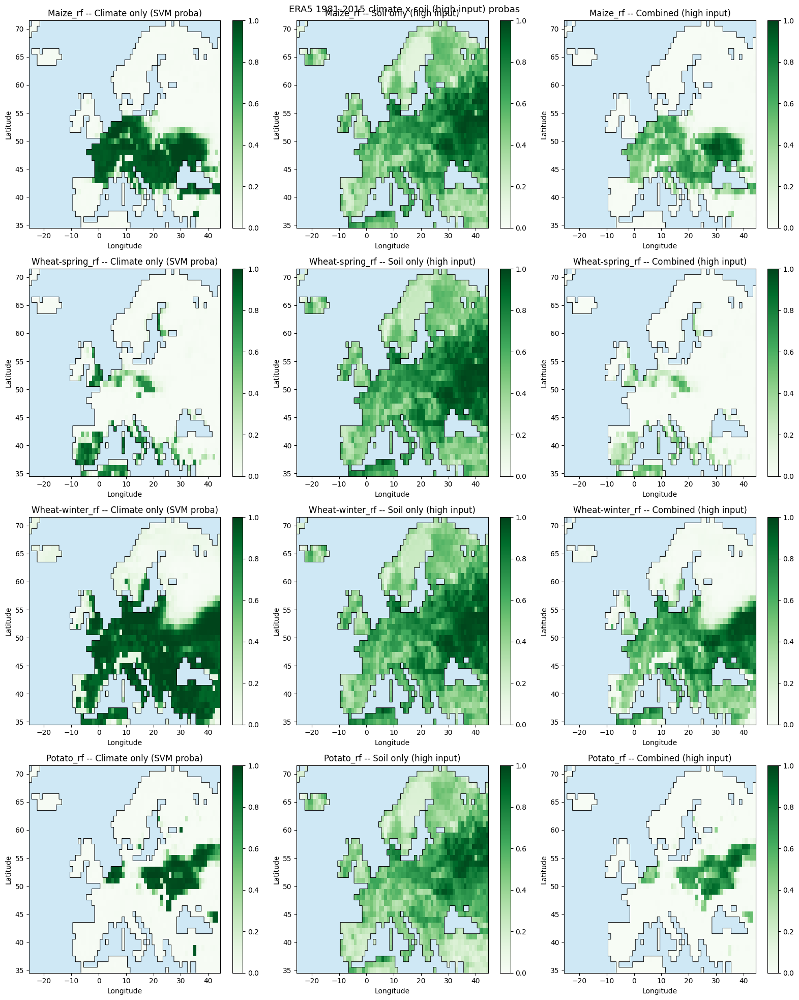

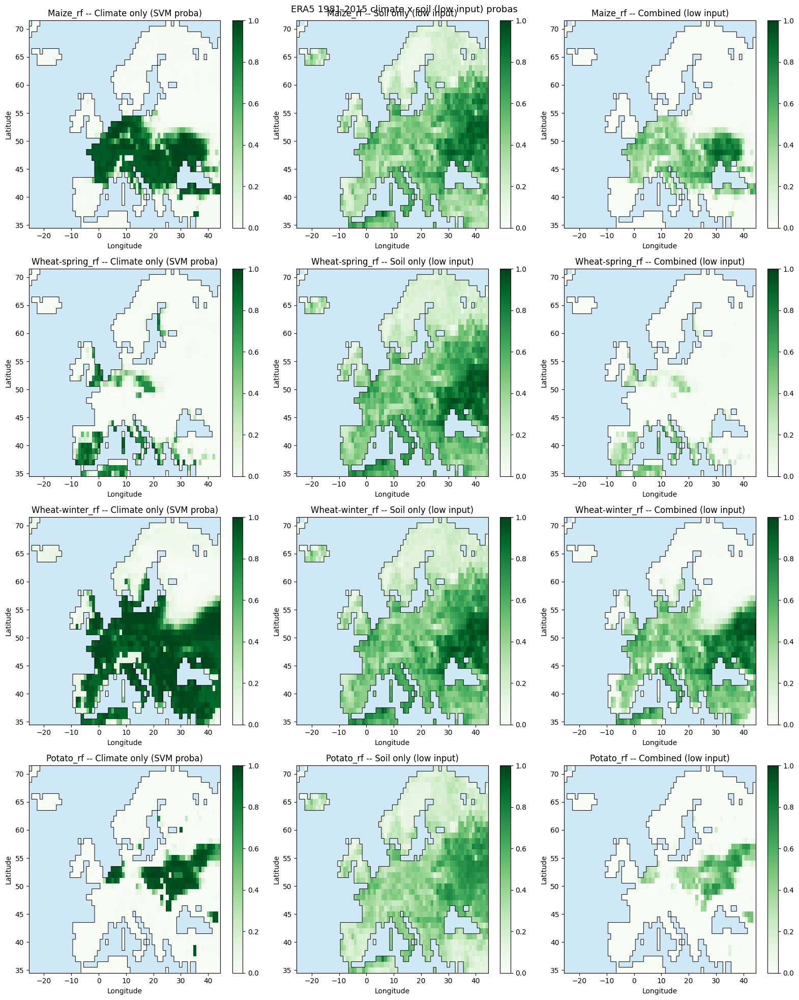

In [4]:
# 'Greens' (contrairement a 'YlGn') part du blanc a 0, pas du jaune pale -- evite la confusion
# visuelle entre '0 = apte a 0%' (une vraie valeur) et 'NaN = hors masque' (transparent, bleu dessous).
WATER_COLOR = '#cfe8f5'
cmap_suit = plt.get_cmap('Greens').copy()
# color=WATER_COLOR (pas juste alpha=0) : a resolution native fine, un pointille dense de NaN
# (ex. les nombreux petits lacs scandinaves dans le raster GAEZ SQ0) se faisait lisser par
# l'antialiasing de l'affichage en melangeant le RGB noir par defaut d'un alpha=0 avec les
# pixels valides voisins -> taches grises au lieu du bleu-eau propre. Couleur explicite = fix.
cmap_suit.set_bad(color=WATER_COLOR)

# contour() interpole une ligne lissee entre CENTRES de pixels -- ca ne suit pas les bords carres
# d'un masque raster binaire. Fix : suréchantillonner le masque par repetition (PAS d'interpolation,
# juste des copies du pixel), puis contourer cette grille fine -- la ligne 0.5 colle alors au vrai
# bord de pixel a mieux que 5% de pixel pres, au lieu de passer par son centre.
_UP = 20
_dlat = target_lats_asc[1] - target_lats_asc[0]
_dlon = target_lons[1] - target_lons[0]
LAND_FINE = np.repeat(np.repeat(land_mask.astype(float), _UP, axis=0), _UP, axis=1)
LAT_FINE = np.linspace(target_lats_asc[0] - 0.5*_dlat + 0.5*_dlat/_UP,
                        target_lats_asc[-1] + 0.5*_dlat - 0.5*_dlat/_UP, land_mask.shape[0]*_UP)
LON_FINE = np.linspace(target_lons[0] - 0.5*_dlon + 0.5*_dlon/_UP,
                        target_lons[-1] + 0.5*_dlon - 0.5*_dlon/_UP, land_mask.shape[1]*_UP)

def draw_coastline(ax):
    ax.contour(LON_FINE, LAT_FINE, LAND_FINE, levels=[0.5], colors='black', linewidths=0.7)

for level in LEVELS:
    fig, axes = plt.subplots(len(CROPS), 3, figsize=(16, 5*len(CROPS)))
    for row, crop in enumerate(CROPS):
        for col, (arr, title) in enumerate([(suit_climate[crop], 'Climate only (SVM proba)'),
                                            (soil_idx[level][crop], f'Soil only ({level} input)'),
                                            (suit_combined[level][crop], f'Combined ({level} input)')]):
            ax = axes[row, col]
            ax.set_facecolor(WATER_COLOR)
            im = ax.imshow(arr, origin='lower', aspect='auto', extent=ext, cmap=cmap_suit, vmin=0, vmax=1)
            draw_coastline(ax)
            ax.set_title(f'{crop} -- {title}')
            plt.colorbar(im, ax=ax)
            ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
    plt.suptitle(f'ERA5 1981-2015 climate x soil ({level} input) probas', fontsize=13)
    plt.tight_layout()
    plt.savefig(OUT_DIR / f'combined_suitability_maps_ERA5_{level}.png', dpi=130)
    plt.show()

## 2. Validation against MIRCA2000

`label` in the training CSV: 1 = currently cultivated, 0 = background. AUC is used rather
than the map's own cutoff because it is threshold-free — the question is whether soil
adds *ranking* information, not whether one particular cutoff happens to look better.

In [5]:
li = {round(x, 1): i for i, x in enumerate(target_lats_asc)}
lj = {round(x, 1): j for j, x in enumerate(target_lons)}

mirca_rows = []
for crop in CROPS:
    train = pd.read_csv(ERA5_DIR / f'training_dataset_ERA5_1deg_{crop}.csv')
    ii = train.lat.round(1).map(li).values; jj = train.lon.round(1).map(lj).values
    layers = [('climate', suit_climate[crop])]
    for level in LEVELS:
        layers += [(f'soil ({level})', soil_idx[level][crop]), (f'combined ({level})', suit_combined[level][crop])]
    for label, arr in layers:
        v = arr[ii, jj]
        sub = pd.DataFrame({'v': v, 'label': train['label']}).dropna()
        cult, bg = sub[sub.label == 1]['v'], sub[sub.label == 0]['v']
        auc = roc_auc_score(sub['label'], sub['v'])
        mirca_rows.append(dict(crop=crop, layer=label, n=len(sub), mean_cultivated=cult.mean(),
                               mean_background=bg.mean(), gap=cult.mean()-bg.mean(), auc=auc))
mirca_summary = pd.DataFrame(mirca_rows).round(3)
print(mirca_summary.to_string(index=False))
mirca_summary.to_csv(OUT_DIR / 'validation_summary_MIRCA2000.csv', index=False)

           crop           layer    n  mean_cultivated  mean_background    gap   auc
       Maize_rf         climate 1332            0.913            0.075  0.838 0.992
       Maize_rf     soil (high) 1330            0.641            0.513  0.128 0.667
       Maize_rf combined (high) 1330            0.587            0.045  0.542 0.980
       Maize_rf      soil (low) 1330            0.545            0.380  0.165 0.726
       Maize_rf  combined (low) 1330            0.499            0.036  0.463 0.982
Wheat-spring_rf         climate 1332            0.770            0.069  0.701 0.972
Wheat-spring_rf     soil (high) 1330            0.534            0.592 -0.058 0.429
Wheat-spring_rf combined (high) 1330            0.403            0.038  0.366 0.967
Wheat-spring_rf      soil (low) 1330            0.476            0.459  0.017 0.537
Wheat-spring_rf  combined (low) 1330            0.369            0.034  0.335 0.965
Wheat-winter_rf         climate 1332            0.912            0.090  0.82

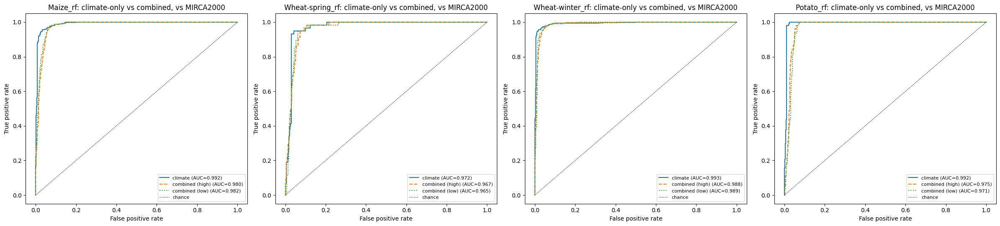

In [6]:
fig, axes = plt.subplots(1, len(CROPS), figsize=(6*len(CROPS), 5.5))
level_style = {'high': '--', 'low': ':'}
for ax, crop in zip(axes, CROPS):
    train = pd.read_csv(ERA5_DIR / f'training_dataset_ERA5_1deg_{crop}.csv')
    ii = train.lat.round(1).map(li).values; jj = train.lon.round(1).map(lj).values
    lines = [('climate', suit_climate[crop], '-')]
    lines += [(f'combined ({level})', suit_combined[level][crop], level_style[level]) for level in LEVELS]
    for label, arr, style in lines:
        v = arr[ii, jj]
        sub = pd.DataFrame({'v': v, 'label': train['label']}).dropna()
        fpr, tpr, _ = roc_curve(sub['label'], sub['v'])
        auc = roc_auc_score(sub['label'], sub['v'])
        ax.plot(fpr, tpr, style, label=f'{label} (AUC={auc:.3f})')
    ax.plot([0, 1], [0, 1], 'k:', lw=1, label='chance')
    ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate')
    ax.set_title(f'{crop}: climate-only vs combined, vs MIRCA2000')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / 'roc_curves_ERA5.png', dpi=130)
plt.show()

## 3. Validation against GAEZ v5 on ERA5 (1981-2000)

GAEZ v5 classifies each pixel into 7 suitability classes (plus "Not suitable" and water),
combining climate, soil and terrain (this pipeline's combined map has no terrain/slope term
yet -- Step 2's Section 5b, pending DEM data). Converted to a continuous score via each
class's mid-point (`SI>85`->0.925 ... `SI>0`->0.05, `Not suitable`->0.0, water->NaN), then
area-averaged to our 1deg grid the same way as `2.b)`'s SQ0 comparison.

Rain-fed, AgERA5, 1981-2000 -- close to our ERA5 1981-2015 reference. Compared at **both**
input levels: High input and Low input, with our own soil (2_GAEZ Module IV) always matched
to the same input level on both sides.

In [7]:
# Real GAEZ v5 class thresholds (SI>85 Very high ... SI>0 Very marginal), confirmed against
# the GAEZ v5 Geospatial Platform legend. Code 8 = Not suitable, 9 = water, 0 = nodata.
GAEZ_SI_MIDPOINTS = {0: np.nan, 1: 0.925, 2: 0.775, 3: 0.625, 4: 0.475, 5: 0.325,
                      6: 0.175, 7: 0.05, 8: 0.0, 9: np.nan}

def load_gaez_v5_six(path):
    with rasterio.open(path) as src:
        res = src.transform.a
        ulx, uly = src.transform.c, src.transform.f
        px_per_deg = round(1.0 / res)
        col_start = round((LON_MIN_EDGE - ulx) / res)
        row_start = round((uly - LAT_MAX_EDGE) / res)
        col_count = round((LON_MAX_EDGE - LON_MIN_EDGE) / res)
        row_count = round((LAT_MAX_EDGE - LAT_MIN_EDGE) / res)
        raw = src.read(1, window=Window(col_start, row_start, col_count, row_count))
    score = np.vectorize(GAEZ_SI_MIDPOINTS.get)(raw).astype(float)
    assert score.shape == (nlat * px_per_deg, nlon * px_per_deg)
    blocks = score.reshape(nlat, px_per_deg, nlon, px_per_deg)
    with np.errstate(invalid='ignore'):
        out = np.nanmean(blocks, axis=(1, 3))[::-1, :]
    return np.where(land_mask, out, np.nan)

gaez_combined, corr_rows = {}, []
for level in LEVELS:
    gaez_combined[level] = {}
    for crop in CROPS:
        gaez_combined[level][crop] = load_gaez_v5_six(GAEZ_V5_SIX[level][crop])
        both = np.isfinite(suit_combined[level][crop]) & np.isfinite(gaez_combined[level][crop]) & land_mask
        r = np.corrcoef(suit_combined[level][crop][both], gaez_combined[level][crop][both])[0, 1]
        corr_rows.append(dict(level=level, crop=crop, n=int(both.sum()), pearson_r=r,
                              our_mean=float(np.nanmean(suit_combined[level][crop][land_mask])),
                              gaez_mean=float(np.nanmean(gaez_combined[level][crop][land_mask]))))
corr_summary = pd.DataFrame(corr_rows).round(3)
print(corr_summary.to_string(index=False))
corr_summary.to_csv(OUT_DIR / 'validation_summary_GAEZv5_SIX.csv', index=False)

level            crop    n  pearson_r  our_mean  gaez_mean
 high        Maize_rf 1330      0.646     0.173      0.168
 high Wheat-spring_rf 1330     -0.016     0.054      0.379
 high Wheat-winter_rf 1330      0.624     0.352      0.379
 high       Potato_rf 1330      0.598     0.093      0.345
  low        Maize_rf 1330      0.638     0.145      0.155
  low Wheat-spring_rf 1330     -0.028     0.048      0.314
  low Wheat-winter_rf 1330      0.673     0.306      0.314
  low       Potato_rf 1330      0.539     0.068      0.288


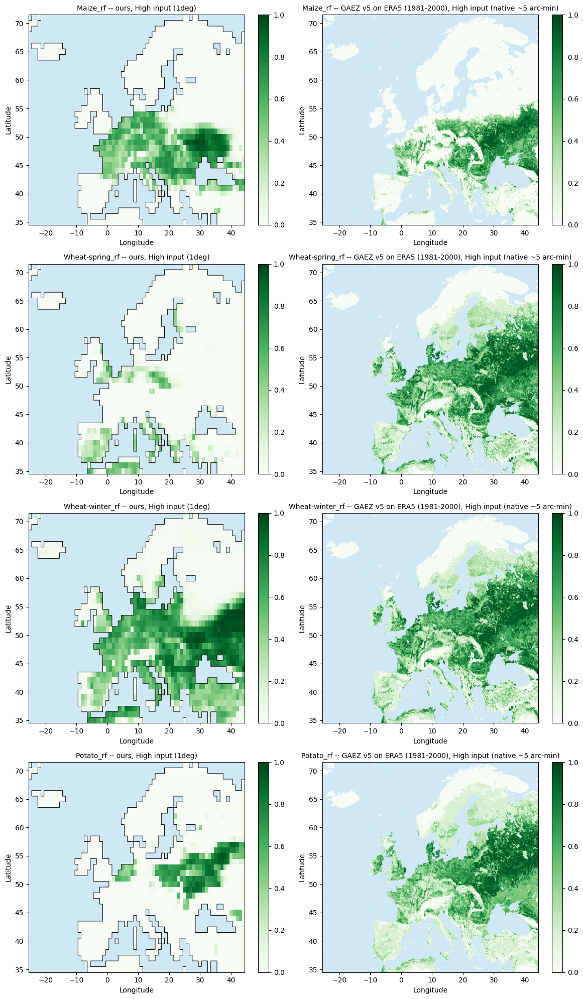

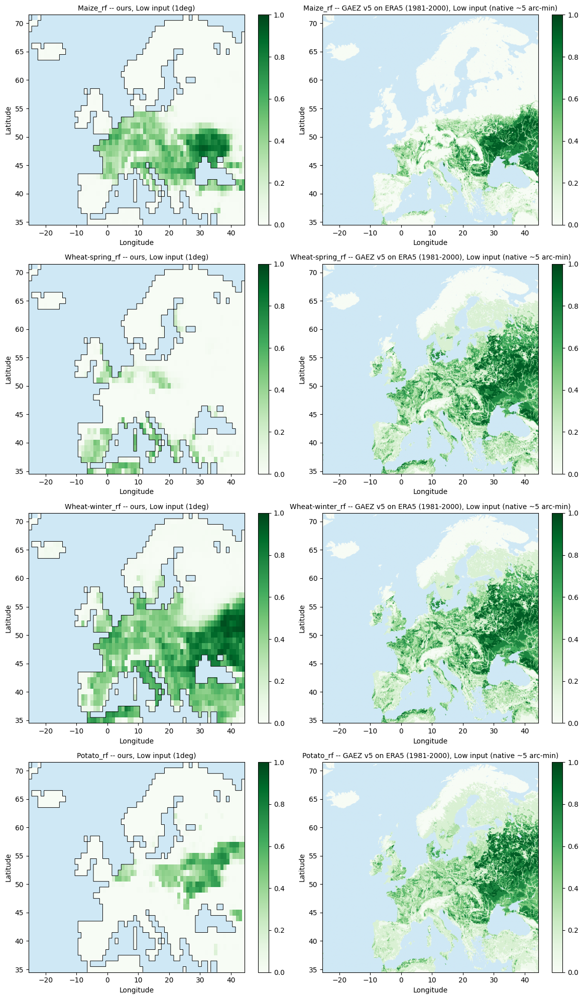

In [8]:
def load_gaez_v5_six_native(path):
    """Same class -> score conversion as load_gaez_v5_six, but NO aggregation to 1deg: returns
    the score at GAEZ's own native 5 arc-min resolution, for display only (the 1deg version is
    still used for the Pearson correlation, which needs a matching grid to compare pixel-by-pixel;
    aggregating for *that* is unavoidable, but the map panel doesn't need to degrade the data)."""
    with rasterio.open(path) as src:
        res = src.transform.a
        ulx, uly = src.transform.c, src.transform.f
        col_start = round((LON_MIN_EDGE - ulx) / res)
        row_start = round((uly - LAT_MAX_EDGE) / res)
        col_count = round((LON_MAX_EDGE - LON_MIN_EDGE) / res)
        row_count = round((LAT_MAX_EDGE - LAT_MIN_EDGE) / res)
        raw = src.read(1, window=Window(col_start, row_start, col_count, row_count))
    return np.vectorize(GAEZ_SI_MIDPOINTS.get)(raw).astype(float)  # north-up, same convention as the raw raster


for level in LEVELS:
    level_word = level.capitalize()
    fig, axes = plt.subplots(len(CROPS), 2, figsize=(12, 5*len(CROPS)))
    for row, crop in enumerate(CROPS):
        gaez_native = load_gaez_v5_six_native(GAEZ_V5_SIX[level][crop])

        ax = axes[row, 0]
        ax.set_facecolor(WATER_COLOR)
        im = ax.imshow(suit_combined[level][crop], origin='lower', aspect='auto', extent=ext, cmap=cmap_suit, vmin=0, vmax=1)
        draw_coastline(ax)
        ax.set_title(f'{crop} -- ours, {level_word} input (1deg)', fontsize=10)
        plt.colorbar(im, ax=ax)
        ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')

        ax = axes[row, 1]
        ax.set_facecolor(WATER_COLOR)
        # origin='upper': raw GAEZ raster is north-up (row 0 = northernmost), no flip needed here
        # (unlike the 1deg block-averaged version, which is reordered to match the ascending-lat grid).
        im = ax.imshow(gaez_native, origin='upper', aspect='auto', extent=ext, cmap=cmap_suit, vmin=0, vmax=1)
        ax.set_title(f'{crop} -- GAEZ v5 on ERA5 (1981-2000), {level_word} input (native ~5 arc-min)', fontsize=10)
        plt.colorbar(im, ax=ax)
        ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
    plt.tight_layout()
    plt.savefig(OUT_DIR / f'combined_vs_gaezv5_SIX_maps_{level}.png', dpi=130)
    plt.show()

## 5. Comparaison a 6 panneaux -- sol seul et combinaisons croisees, resolution native

Pour chaque crop/niveau d'input, un seul schema avec les 4 "sources" cote a cote : climat seul
(SVM), sol seul (nous vs GAEZ v5), combine (notre climat x notre sol, et notre climat x le sol
GAEZ), et le produit GAEZ v5 complet (climat+sol+terrain integres par GAEZ lui-meme).

**Sol seul, nous** : reconstruit directement depuis `_soil_suitability_by_smu.pkl` (le tableau par
SMU produit par `2.c)`, pas les fichiers `x0grid` 1deg de `2.e)`) en lisant le raster HWSD natif
(30 arc-sec) restreint a notre emprise Europe et en moyennant par blocs de 10 pixels natifs
(10 x 30 arc-sec = 5 arc-min) -- meme resolution que le produit GAEZ natif, pour une comparaison
visuelle directe sans degrader nos donnees a 1deg.

**Sol seul, GAEZ v5** : raster officiel `SQX.SQ0` (deja telecharge par `2.d)` -- HIM/LIM, le meme
fichier que celui utilise pour la validation composant par composant). **Attention** : ce produit
est documente par GAEZ comme "using maize as the reference crop" -- il n'existe **pas** de version
specifique au ble. On l'utilise donc pour les 3 cultures en l'etiquetant explicitement comme
reference mais generique (pas cultive-specifique) pour Wheat-spring/Wheat-winter.

**Climat x sol GAEZ (1deg)** : nouvelle combinaison. Le raster SQ0 (classes 1-10, meme convention
que SIX mais bins uniformes de 10%) est regrille a 1deg exactement comme `load_gaez_v5_six` (bloc
`nanmean` sur les pixels natifs tombant dans chaque cellule 1deg, puis masque par `land_mask`),
puis multiplie par notre `suit_climate` (meme logique continue que pour notre propre sol).


In [9]:
import matplotlib.colors as mcolors
from rasterio.transform import rowcol

HWSD_TIF = cu.data_file(CFG, "hwsd_raster")  # data path: see 00_config_and_inventory.ipynb
assert HWSD_TIF.exists(), HWSD_TIF

_ssr_all = pd.read_pickle(SOIL_DIR.parent / "_soil_suitability_by_smu.pkl")
_max_smu_all = int(_ssr_all['SMU_ID'].max())
_LEVEL_COL = {'low': 'SSR_low', 'high': 'SSR_high'}

FAO_SQ0_PATHS = {'high': SOIL_DIR / "_validation_fao_sqx_sq0_maize_him.tif",
                 'low': SOIL_DIR / "_validation_fao_sqx_sq0_maize_lim.tif"}
for p in FAO_SQ0_PATHS.values():
    assert p.exists(), f"Missing (run 2.d first): {p}"


def our_soil_crop_regime(crop_label):
    regime = crop_label.split('_')[-1]
    crop_name = 'Wheat' if crop_label.startswith('Wheat') else crop_label.split('_')[0]
    return crop_name, regime


def aggregate_our_soil_native(crop_label, level, agg=10):
    """Notre SSR par SMU, lu au natif HWSD (30 arc-sec) sur notre emprise Europe et moyenne par
    blocs de `agg` pixels natifs (agg=10 -> ~5 arc-min, resolution GAEZ). North-up (pas de flip),
    pour un affichage direct a cote des rasters GAEZ natifs (meme convention origin='upper')."""
    crop_name, regime = our_soil_crop_regime(crop_label)
    sub = _ssr_all[(_ssr_all['crop'] == crop_name) & (_ssr_all['regime'] == regime)]
    lut = np.full(_max_smu_all + 1, np.nan, dtype=np.float32)
    lut[sub['SMU_ID'].values.astype(int)] = sub[_LEVEL_COL[level]].values.astype(np.float32)
    with rasterio.open(HWSD_TIF) as src:
        nodata = src.nodata
        r0, c0 = rowcol(src.transform, LON_MIN_EDGE, LAT_MAX_EDGE)
        h, w = nlat * 120, nlon * 120  # 120 pixels natifs (30 arc-sec) par cellule 1deg
        block = src.read(1, window=Window(c0, r0, w, h))
    valid = (block != nodata) & (block <= _max_smu_all)
    vals = np.full(block.shape, np.nan, dtype=np.float32)
    vals[valid] = lut[block[valid]]
    out_h, out_w = h // agg, w // agg
    vals_r = vals.reshape(out_h, agg, out_w, agg)
    with np.errstate(invalid='ignore'):
        acc = np.nanmean(vals_r, axis=(1, 3))
    return acc / 100.0


def _sq0_midpoints(raw):
    mid = raw.astype(float)
    mid = (mid - 0.5) * 10.0
    mid[(raw < 1) | (raw > 10)] = np.nan
    return mid


def load_gaez_sq0_native(path):
    """Meme logique que load_gaez_v5_six_native, mais pour le raster SQ0 (sol seul, classes 1-10,
    bins uniformes de 10% -- pas la meme convention que GAEZ_SI_MIDPOINTS utilisee pour SIX)."""
    with rasterio.open(path) as src:
        res = src.transform.a
        ulx, uly = src.transform.c, src.transform.f
        col_start = round((LON_MIN_EDGE - ulx) / res)
        row_start = round((uly - LAT_MAX_EDGE) / res)
        col_count = round((LON_MAX_EDGE - LON_MIN_EDGE) / res)
        row_count = round((LAT_MAX_EDGE - LAT_MIN_EDGE) / res)
        raw = src.read(1, window=Window(col_start, row_start, col_count, row_count))
    return _sq0_midpoints(raw) / 100.0


def load_gaez_sq0_1deg(path):
    """Meme logique que load_gaez_v5_six (regrillage 1deg, masque land_mask), pour SQ0."""
    with rasterio.open(path) as src:
        res = src.transform.a
        ulx, uly = src.transform.c, src.transform.f
        px_per_deg = round(1.0 / res)
        col_start = round((LON_MIN_EDGE - ulx) / res)
        row_start = round((uly - LAT_MAX_EDGE) / res)
        col_count = round((LON_MAX_EDGE - LON_MIN_EDGE) / res)
        row_count = round((LAT_MAX_EDGE - LAT_MIN_EDGE) / res)
        raw = src.read(1, window=Window(col_start, row_start, col_count, row_count))
    mid = _sq0_midpoints(raw) / 100.0
    assert mid.shape == (nlat * px_per_deg, nlon * px_per_deg)
    blocks = mid.reshape(nlat, px_per_deg, nlon, px_per_deg)
    with np.errstate(invalid='ignore'):
        out = np.nanmean(blocks, axis=(1, 3))[::-1, :]
    return np.where(land_mask, out, np.nan)


NODATA_GREY = "#9e9e9e"  # SQ0 classes 11-14: evaluated but not on the 1-10 suitability
# scale (not documented further by GAEZ in what we have -- likely water bodies/urban/other land
# cover). Kept visually distinct from true nodata/ocean (raw==0, shown as WATER_COLOR blue).


def load_gaez_sq0_native_rgba(path):
    """Like load_gaez_sq0_native, but returns a precomputed RGBA image instead of a float array +
    cmap/vmin/vmax: raw==0 (true nodata/outside domain) stays fully transparent (shows the blue
    WATER_COLOR facecolor); raw 11-14 (other non-rated classes) are painted opaque grey; raw 1-10
    use the normal green suitability gradient."""
    with rasterio.open(path) as src:
        res = src.transform.a
        ulx, uly = src.transform.c, src.transform.f
        col_start = round((LON_MIN_EDGE - ulx) / res)
        row_start = round((uly - LAT_MAX_EDGE) / res)
        col_count = round((LON_MAX_EDGE - LON_MIN_EDGE) / res)
        row_count = round((LAT_MAX_EDGE - LAT_MIN_EDGE) / res)
        raw = src.read(1, window=Window(col_start, row_start, col_count, row_count))
    mid01 = np.clip((_sq0_midpoints(raw)) / 100.0, 0.0, 1.0)
    rated = (raw >= 1) & (raw <= 10)
    other = (raw >= 11) & (raw <= 14)
    rgba = np.zeros(raw.shape + (4,), dtype=float)  # default: fully transparent (raw==0 / anything else)
    rgba[rated] = cmap_suit(mid01[rated])
    grey_rgba = np.array(mcolors.to_rgba(NODATA_GREY))
    rgba[other] = grey_rgba
    return rgba


soil_gaez_native, soil_gaez_native_rgba, soil_gaez_1deg, suit_combined_gaezsoil = {}, {}, {}, {}
for level in LEVELS:
    soil_gaez_native[level] = load_gaez_sq0_native(FAO_SQ0_PATHS[level])
    soil_gaez_native_rgba[level] = load_gaez_sq0_native_rgba(FAO_SQ0_PATHS[level])
    soil_gaez_1deg[level] = load_gaez_sq0_1deg(FAO_SQ0_PATHS[level])
    suit_combined_gaezsoil[level] = {crop: suit_climate[crop] * soil_gaez_1deg[level] for crop in CROPS}
    print(f'{level:5s} GAEZ soil (maize ref) mean (1deg, land only): '
          f'{np.nanmean(soil_gaez_1deg[level][land_mask]):.3f}')


high  GAEZ soil (maize ref) mean (1deg, land only): 0.593


low   GAEZ soil (maize ref) mean (1deg, land only): 0.473


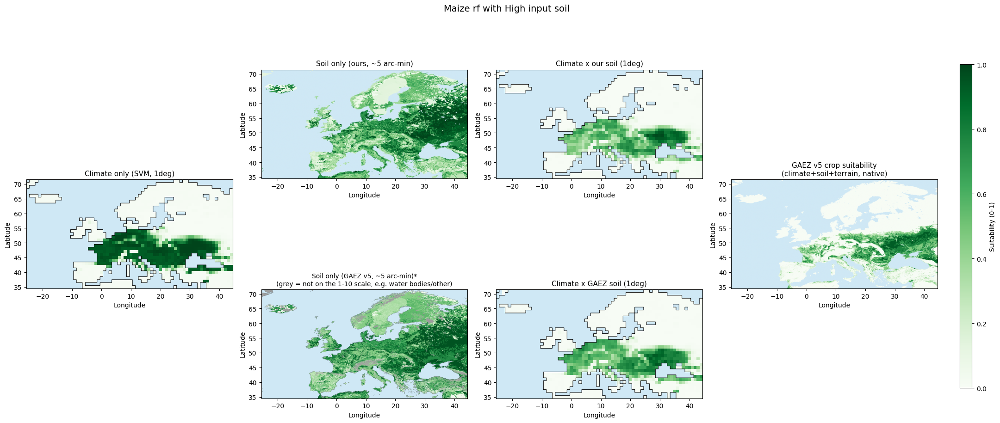

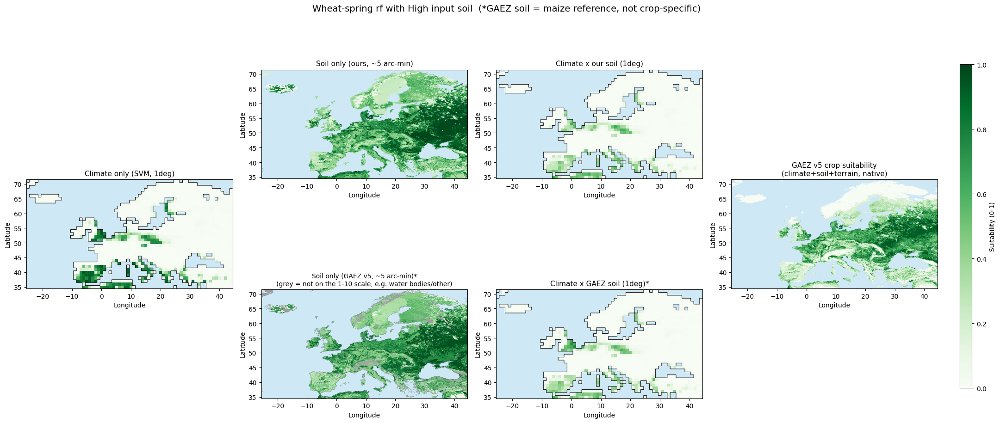

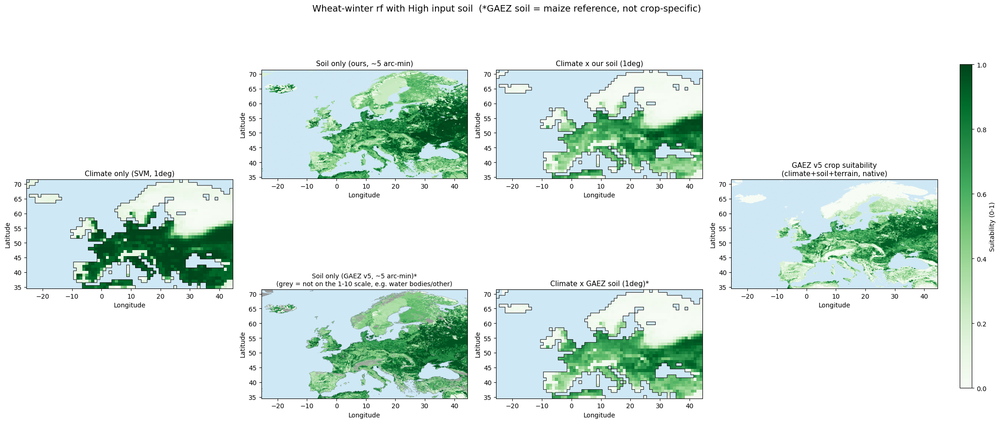

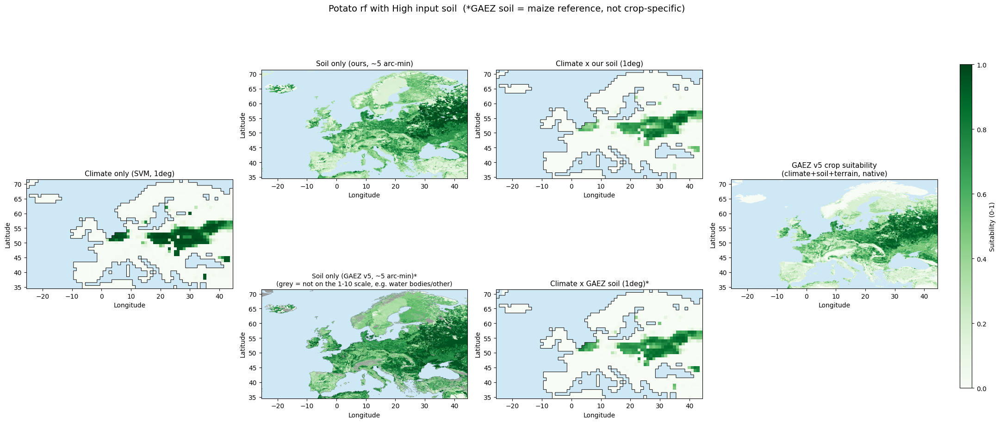

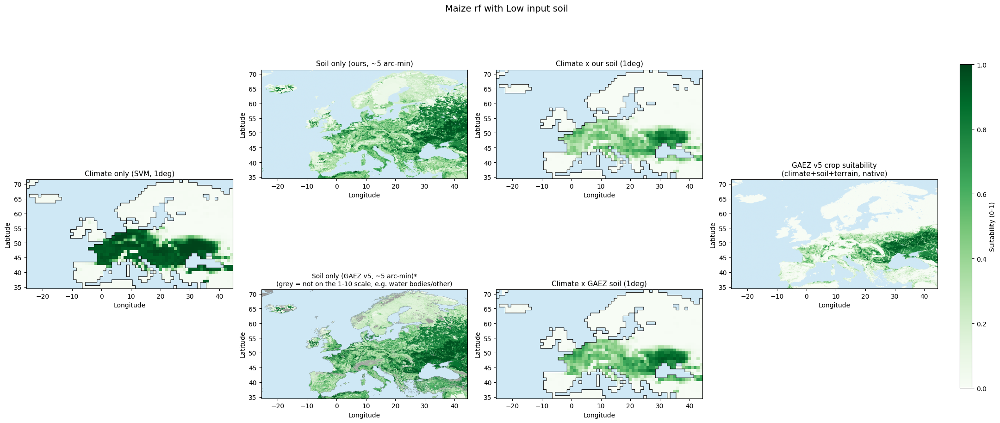

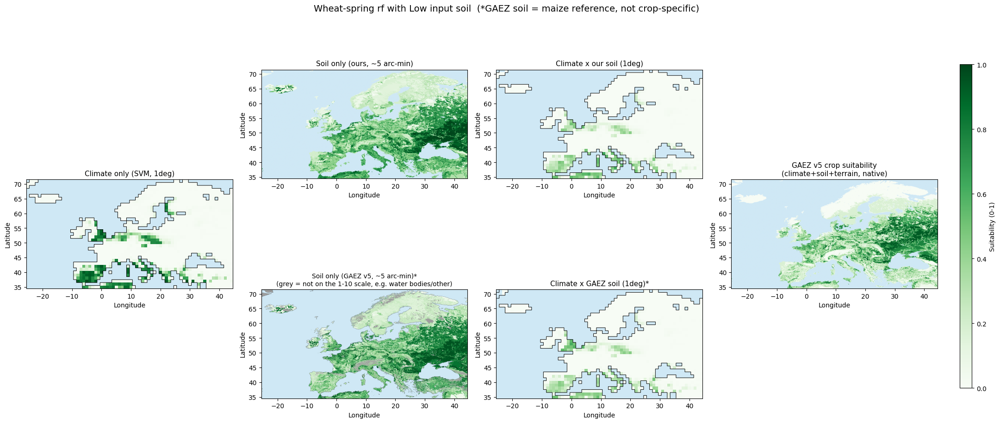

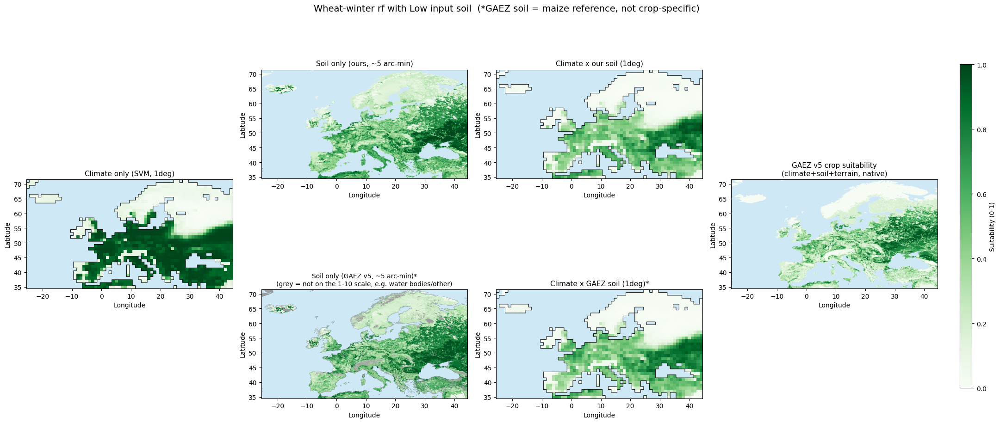

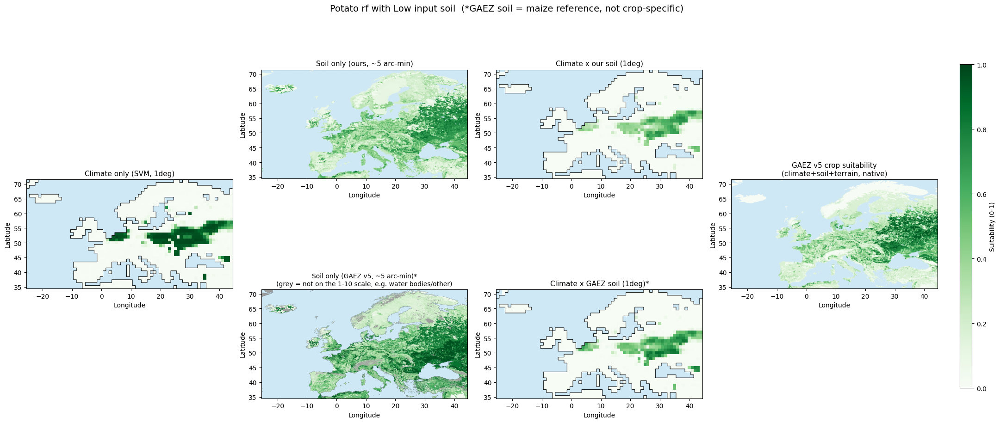

In [10]:
for level in LEVELS:
    level_word = level.capitalize()
    for crop in CROPS:
        soil_ours_native = aggregate_our_soil_native(crop, level, agg=10)
        gaez_star = '' if crop == 'Maize_rf' else '*'  # for Maize_rf the GAEZ SQ0 raster IS the real maize-specific data, no caveat needed
        gaez_native_full = load_gaez_v5_six_native(GAEZ_V5_SIX[level][crop])

        # Une seule colorbar partagee (0-1 pour les 6 panneaux) au lieu d'une par panneau --
        # redondant sinon, et ca laisse plus de place pour agrandir les cartes elles-memes.
        fig = plt.figure(figsize=(22, 10))
        gs = fig.add_gridspec(2, 4)
        map_axes = []

        ax = fig.add_subplot(gs[:, 0])
        ax.set_facecolor(WATER_COLOR)
        im = ax.imshow(suit_climate[crop], origin='lower', aspect='equal', extent=ext, cmap=cmap_suit, vmin=0, vmax=1)
        draw_coastline(ax)
        ax.set_title('Climate only (SVM, 1deg)', fontsize=11)
        map_axes.append(ax)

        ax = fig.add_subplot(gs[0, 1])
        ax.set_facecolor(WATER_COLOR)
        im = ax.imshow(soil_ours_native, origin='upper', aspect='equal', extent=ext, cmap=cmap_suit, vmin=0, vmax=1)
        ax.set_title('Soil only (ours, ~5 arc-min)', fontsize=11)
        map_axes.append(ax)

        ax = fig.add_subplot(gs[1, 1])
        ax.set_facecolor(WATER_COLOR)
        ax.imshow(soil_gaez_native_rgba[level], origin='upper', aspect='equal', extent=ext)
        ax.set_title('Soil only (GAEZ v5, ~5 arc-min)*\n(grey = not on the 1-10 scale, e.g. water bodies/other)', fontsize=10)
        map_axes.append(ax)

        ax = fig.add_subplot(gs[0, 2])
        ax.set_facecolor(WATER_COLOR)
        im = ax.imshow(suit_combined[level][crop], origin='lower', aspect='equal', extent=ext, cmap=cmap_suit, vmin=0, vmax=1)
        draw_coastline(ax)
        ax.set_title('Climate x our soil (1deg)', fontsize=11)
        map_axes.append(ax)

        ax = fig.add_subplot(gs[1, 2])
        ax.set_facecolor(WATER_COLOR)
        im = ax.imshow(suit_combined_gaezsoil[level][crop], origin='lower', aspect='equal', extent=ext, cmap=cmap_suit, vmin=0, vmax=1)
        draw_coastline(ax)
        ax.set_title(f'Climate x GAEZ soil (1deg){gaez_star}', fontsize=11)
        map_axes.append(ax)

        ax = fig.add_subplot(gs[:, 3])
        ax.set_facecolor(WATER_COLOR)
        im = ax.imshow(gaez_native_full, origin='upper', aspect='equal', extent=ext, cmap=cmap_suit, vmin=0, vmax=1)
        ax.set_title('GAEZ v5 crop suitability\n(climate+soil+terrain, native)', fontsize=11)
        map_axes.append(ax)

        for a in map_axes:
            a.set_xlabel('Longitude'); a.set_ylabel('Latitude')

        star_note = '  (*GAEZ soil = maize reference, not crop-specific)' if crop != 'Maize_rf' else ''
        plt.suptitle(f'{crop.replace("_", " ")} with {level_word} input soil' + star_note, fontsize=14)
        plt.tight_layout(rect=[0, 0, 0.93, 1])
        cbar_ax = fig.add_axes([0.945, 0.15, 0.012, 0.7])
        fig.colorbar(im, cax=cbar_ax, label='Suitability (0-1)')
        plt.savefig(OUT_DIR / f'six_panel_{crop}_{level}.png', dpi=130, bbox_inches='tight', pad_inches=0.15)
        plt.show()


## 6. Comparaison a 4 panneaux -- verite terrain MIRCA2000, climat, combine, GAEZ v5

MIRCA2000 (verite terrain) | climat seul (SVM, 1deg) | climat x notre sol (1deg) | GAEZ v5
complet (resolution native), cote a cote.

**MIRCA2000 a resolution native** : reconstruit directement depuis le calendrier cultural brut
(`CELL_SPECIFIC_CROPPING_CALENDARS.TXT.gz`, 5 arc-min), avec exactement la meme logique et le
meme seuil (`CROP_THR = 0.05`, soit > 5% de la surface du pixel cultivee) que ceux utilises pour
construire le label d'entrainement 1deg du SVM (`0_preprocessing_masks/0.1)_preprocessing_input_data.ipynb`,
section 2). Donc coherent avec le fond de verite qui a servi a entrainer le modele -- pas une
nouvelle definition, juste la meme a resolution native plutot qu'agregee a 1deg.


In [11]:
# ---- MIRCA2000 a resolution native (5 arc-min), meme definition que le label d'entrainement 1deg
# (voir 0_preprocessing_masks/0.1)_preprocessing_input_data.ipynb, section 2 -- logique reprise ici a
# l'identique, restreinte a Maize/Wheat rf et a notre emprise Europe).
CAL_FILE = BASE / "0_Input_data" / "masks_crops" / "MIRCA_2000" / "growing_periods_listed" / "CELL_SPECIFIC_CROPPING_CALENDARS.TXT.gz"
CELL_AREA_FILE = BASE / "0_Input_data" / "masks_crops" / "MIRCA_2000" / "cell_area_grid" / "cell_area_ha.npy"
CROP_THR = 0.05
assert CAL_FILE.exists() and CELL_AREA_FILE.exists()

LAT0, LAT1 = int(target_lats_asc.min()), int(target_lats_asc.max())
LON0, LON1 = int(target_lons.min()), int(target_lons.max())
NLAT_, NLON_ = LAT1 - LAT0 + 1, LON1 - LON0 + 1

NROW, NCOL = 2160, 4320
ROWS_, COLS_ = np.arange(NROW), np.arange(NCOL)
lat5 = 90 - (ROWS_ + 0.5) / 12
lon5 = -180 + (COLS_ + 0.5) / 12
lat5_i = np.floor(lat5 + 0.5).astype(int)
lon5_i = np.floor(lon5 + 0.5).astype(int)
R5 = np.where((lat5_i >= LAT0) & (lat5_i <= LAT1))[0]
C5 = np.where((lon5_i >= LON0) & (lon5_i <= LON1))[0]
AREA5 = np.load(CELL_AREA_FILE)[np.ix_(R5, C5)]  # ha per 5 arc-min pixel

import regionmask
land_rg = regionmask.defined_regions.natural_earth_v5_0_0.land_10
land5 = np.isfinite(land_rg.mask(lon5[C5], lat5[R5]).values)

CAL_CLASSES = {"Wheat": (1, 27), "Maize": (2, 28), "Potato": (10, 36)}
cols_ = ["cell", "row", "col", "lat", "lon", "crop", "subcrop", "area", "start", "end"]
cal = pd.read_csv(CAL_FILE, sep="\t", compression="gzip", usecols=range(10), header=0, names=cols_)
allc = [c for v in CAL_CLASSES.values() for c in v]
cal = cal[cal.crop.isin(allc)].copy()
row_map = {r: i for i, r in enumerate(R5)}
col_map = {c: j for j, c in enumerate(C5)}
cal["i"] = (cal.row - 1).map(row_map)
cal["j"] = (cal.col - 1).map(col_map)
cal = cal.dropna(subset=["i", "j"])
cal["i"] = cal.i.astype(int); cal["j"] = cal.j.astype(int)
cal["irr"] = np.where(cal.crop <= 26, "ir", "rf")
name_of = {c: k for k, v in CAL_CLASSES.items() for c in v}
cal["crop_name"] = cal.crop.map(name_of)

mirca_native_presence = {}  # crop_label -> float array (len(R5), len(C5)), 0/1, north-up
for crop_name, g_all in cal.groupby("crop_name"):
    g = g_all[g_all.irr == 'rf']
    if g.empty:
        continue
    if crop_name == "Wheat":
        seasons = {"spring": g[g.start.isin([2, 3, 4, 5])], "winter": g[g.start.isin([9, 10, 11, 12])]}
    else:
        seasons = {"": g}
    for sname, gs in seasons.items():
        label = f"{crop_name}{'-' + sname if sname else ''}_rf"
        if label not in CROPS:
            continue
        ii, jj, ar = gs.i.values, gs.j.values, gs.area.values
        A = np.zeros((len(R5), len(C5)))
        np.add.at(A, (ii, jj), ar)
        cropped = land5 & ((A / AREA5) > CROP_THR)
        mirca_native_presence[label] = np.where(land5, cropped.astype(float), np.nan)

print('MIRCA native presence pixel counts:', {k: int(np.nansum(v)) for k, v in mirca_native_presence.items()})

mirca_1deg_presence = {}  # crop_label -> float array (nlat, nlon), same grid/orientation as suit_climate
for crop in CROPS:
    train = pd.read_csv(ERA5_DIR / f'training_dataset_ERA5_1deg_{crop}.csv')
    ii = train.lat.round(1).map(li).values
    jj = train.lon.round(1).map(lj).values
    grid = np.full((nlat, nlon), np.nan)
    grid[ii, jj] = train['label'].values
    mirca_1deg_presence[crop] = grid


MIRCA native presence pixel counts: {'Maize_rf': 20371, 'Potato_rf': 5185, 'Wheat-spring_rf': 1956, 'Wheat-winter_rf': 54561}


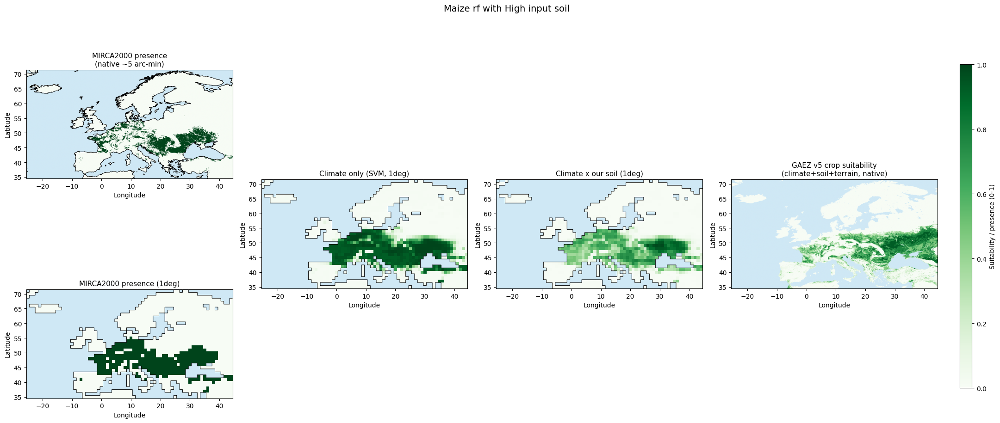

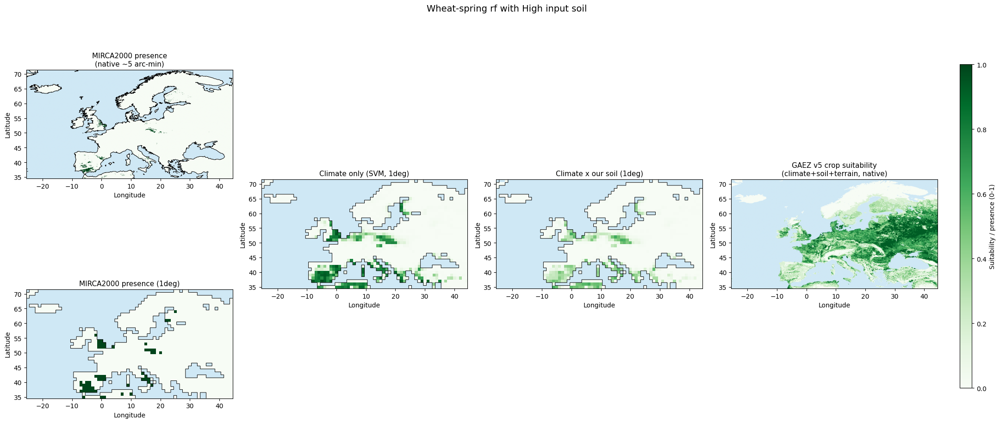

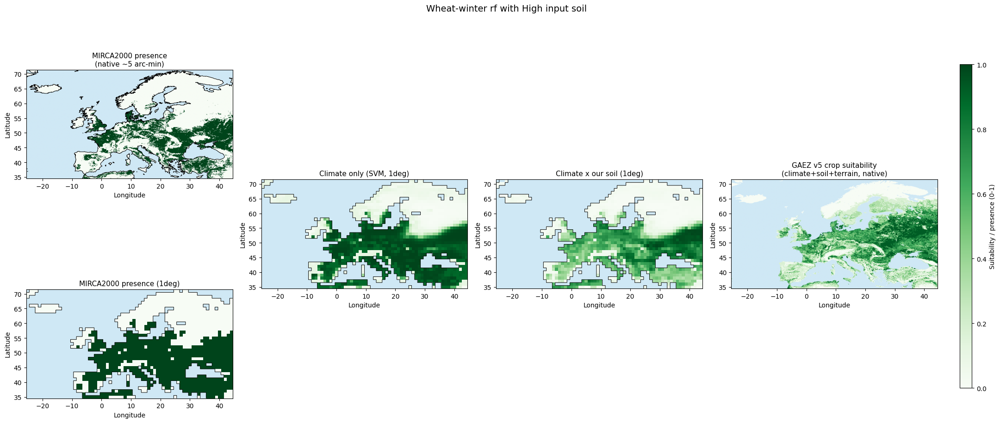

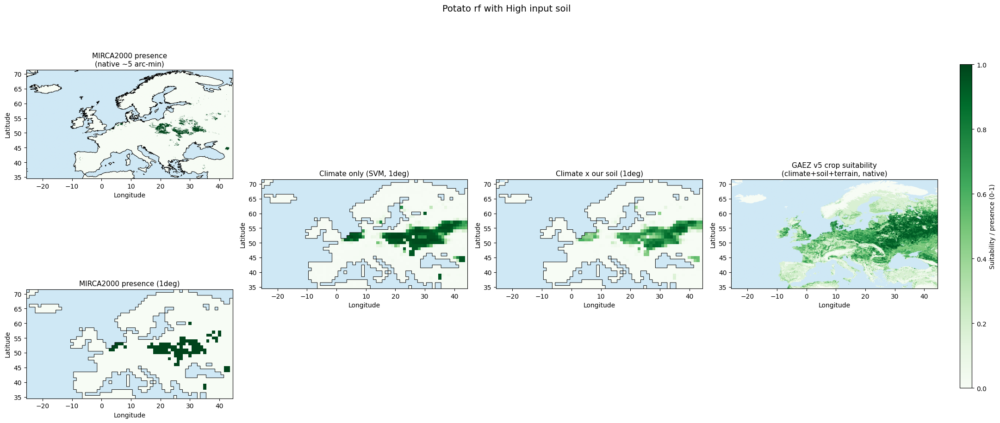

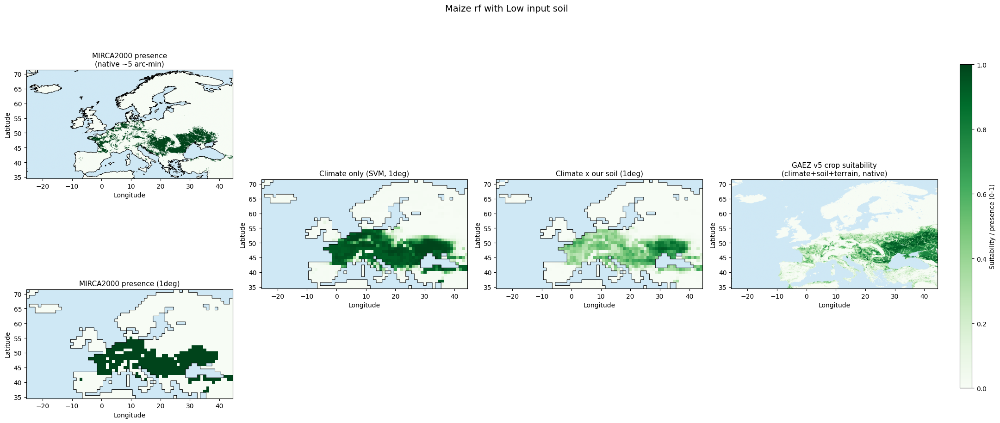

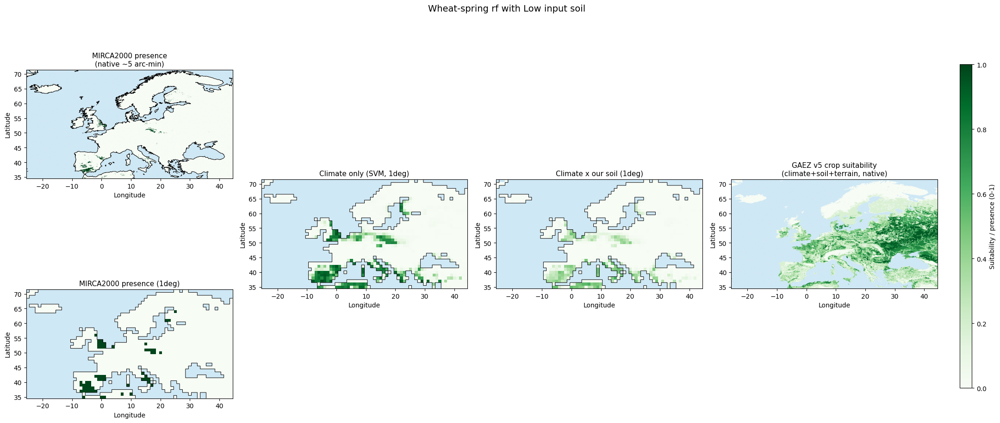

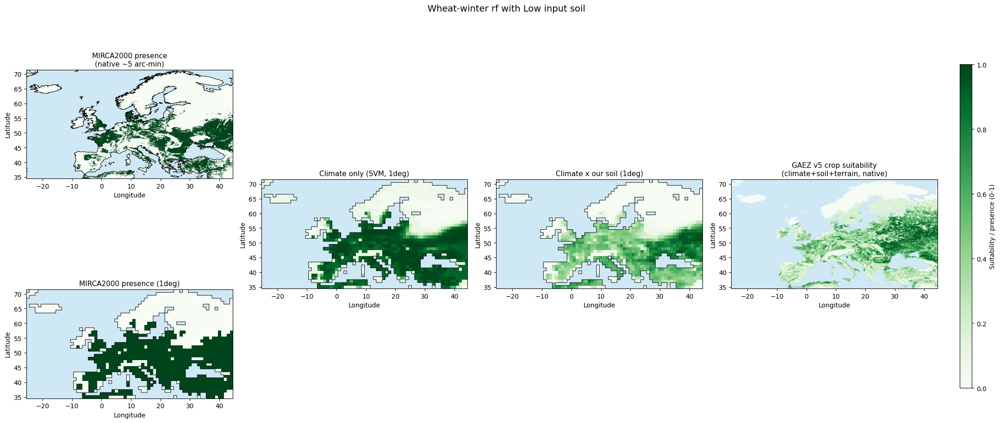

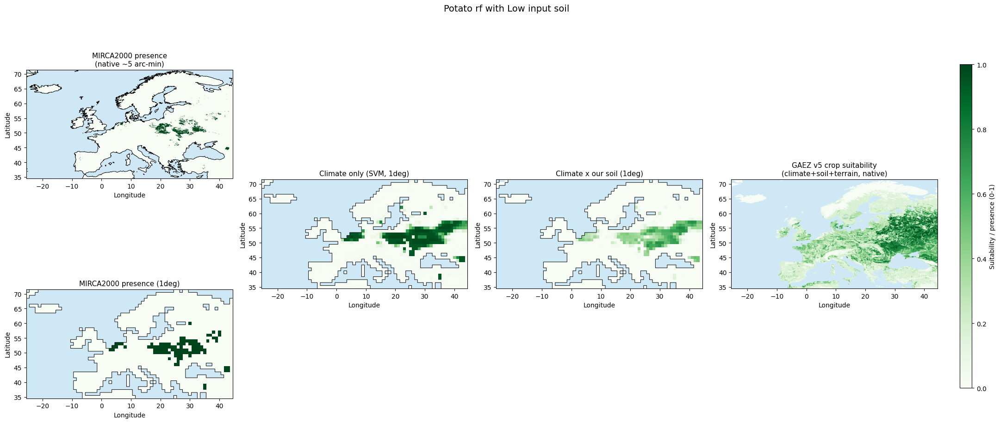

In [12]:
for level in LEVELS:
    level_word = level.capitalize()
    for crop in CROPS:
        gaez_native_full = load_gaez_v5_six_native(GAEZ_V5_SIX[level][crop])
        mirca_native = mirca_native_presence.get(crop)
        mirca_1deg = mirca_1deg_presence.get(crop)

        fig = plt.figure(figsize=(22, 10))
        gs = fig.add_gridspec(2, 4)
        map_axes = []

        ax = fig.add_subplot(gs[0, 0])
        ax.set_facecolor(WATER_COLOR)
        im = ax.imshow(mirca_native, origin='upper', aspect='equal', extent=ext, cmap=cmap_suit, vmin=0, vmax=1)
        ax.contour(lon5[C5], lat5[R5], land5, levels=[0.5], colors='black', linewidths=0.7)
        ax.set_title('MIRCA2000 presence\n(native ~5 arc-min)', fontsize=11)
        map_axes.append(ax)

        ax = fig.add_subplot(gs[1, 0])
        ax.set_facecolor(WATER_COLOR)
        im = ax.imshow(mirca_1deg, origin='lower', aspect='equal', extent=ext, cmap=cmap_suit, vmin=0, vmax=1)
        draw_coastline(ax)
        ax.set_title('MIRCA2000 presence (1deg)', fontsize=11)
        map_axes.append(ax)

        ax = fig.add_subplot(gs[:, 1])
        ax.set_facecolor(WATER_COLOR)
        im = ax.imshow(suit_climate[crop], origin='lower', aspect='equal', extent=ext, cmap=cmap_suit, vmin=0, vmax=1)
        draw_coastline(ax)
        ax.set_title('Climate only (SVM, 1deg)', fontsize=11)
        map_axes.append(ax)

        ax = fig.add_subplot(gs[:, 2])
        ax.set_facecolor(WATER_COLOR)
        im = ax.imshow(suit_combined[level][crop], origin='lower', aspect='equal', extent=ext, cmap=cmap_suit, vmin=0, vmax=1)
        draw_coastline(ax)
        ax.set_title('Climate x our soil (1deg)', fontsize=11)
        map_axes.append(ax)

        ax = fig.add_subplot(gs[:, 3])
        ax.set_facecolor(WATER_COLOR)
        im = ax.imshow(gaez_native_full, origin='upper', aspect='equal', extent=ext, cmap=cmap_suit, vmin=0, vmax=1)
        ax.set_title('GAEZ v5 crop suitability\n(climate+soil+terrain, native)', fontsize=11)
        map_axes.append(ax)

        for a in map_axes:
            a.set_xlabel('Longitude'); a.set_ylabel('Latitude')

        plt.suptitle(f'{crop.replace("_", " ")} with {level_word} input soil', fontsize=14)
        plt.tight_layout(rect=[0, 0, 0.93, 1])
        cbar_ax = fig.add_axes([0.945, 0.15, 0.012, 0.7])
        fig.colorbar(im, cax=cbar_ax, label='Suitability / presence (0-1)')
        plt.savefig(OUT_DIR / f'four_panel_mirca_climate_combined_gaez_{crop}_{level}.png',
                    dpi=130, bbox_inches='tight', pad_inches=0.15)
        plt.show()


## 4. Binary map (suitable / not suitable) on ERA5

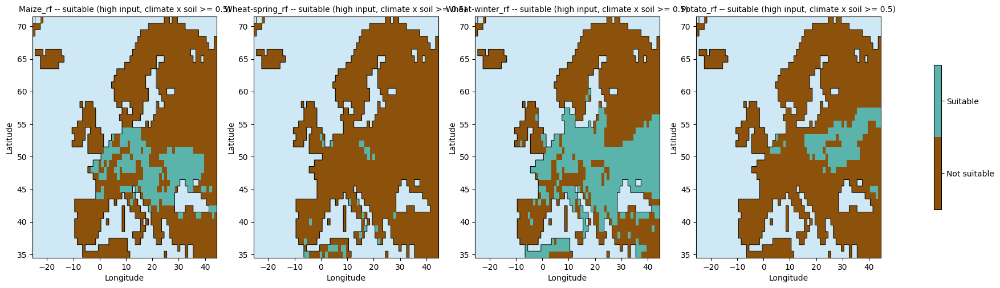

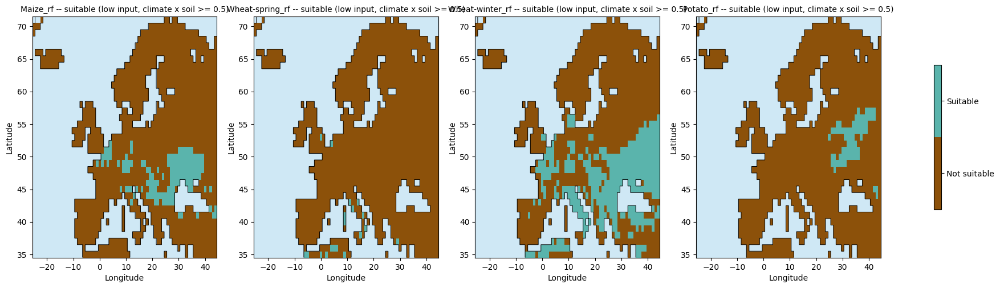

In [13]:
for level in LEVELS:
    fig, axes = plt.subplots(1, len(CROPS), figsize=(6*len(CROPS), 5.5))
    import matplotlib.colors as mcolors
    cmap_bin = mcolors.ListedColormap(['#8c510a', '#5ab4ac'])
    cmap_bin.set_bad(alpha=0)
    for ax, crop in zip(axes, CROPS):
        ax.set_facecolor(WATER_COLOR)
        im = ax.imshow(suit_combined_bin[level][crop], origin='lower', aspect='auto', extent=ext, cmap=cmap_bin, vmin=0, vmax=1)
        draw_coastline(ax)
        ax.set_title(f'{crop} -- suitable ({level} input, climate x soil >= 0.5)', fontsize=10)
        ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
    cbar = plt.colorbar(im, ax=axes, ticks=[0.25, 0.75], shrink=0.6)
    cbar.ax.set_yticklabels(['Not suitable', 'Suitable'])
    plt.savefig(OUT_DIR / f'combined_suitability_binary_ERA5_{level}.png', dpi=130, bbox_inches='tight')
    plt.show()

## Conclusion

Two independent checks, read together: MIRCA2000 (Section 2) tests whether soil adds real
signal beyond the climate model's own training fit; GAEZ v5 SIX (Section 3) tests whether
our combined map, missing only a terrain/slope term, agrees with an independently-built
combined product, at both high and low input levels, with soil on both sides always using
the same input-level assumption. Both are approximate by construction (MIRCA is the SVM's
training target; GAEZ's HP8100 baseline is 1981-2000, not exactly our 1981-2015 ERA5 window,
and includes terrain where ours does not yet) -- consistent, non-contradictory results
across both give grounds to trust the combined climate x soil approach when applied to the
AMOC-hosing scenario in Step 5b; a clear disagreement in either would point to revisiting
the SVM or the soil layer specifically, as identified by which check fails.